📊 Projeto Final: Modelo de Classificação para Risco de Crédito

Objetivo: Desenvolver um algoritmo de machine learning capaz de classificar clientes em bons ou maus pagadores com base em dados financeiros e demográficos, como renda anual e faixa etária. O modelo foca em prever a probabilidade de inadimplência a partir do histórico de crédito, trazendo maior precisão analítica e automação para apoiar a tomada de decisão na concessão.

**Autores:** Eduardo Roquette / Fernando Araújo / Gustavo Bogéa

**Data:** Novembro/2026

In [1]:
# IMPORT DAS BIBLIOTECAS / CONFIGURAÇÃOES PRÉVIAS / LEITURA DA BASE 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score, confusion_matrix
from xgboost import XGBClassifier

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 130)

ARQUIVO_CADASTRO = r'C:\Users\edu_b\OneDrive\CaixaVerso - Formação Continuada\credit-risk-predictor\dados\application_record.csv'
ARQUIVO_CREDITO = r'C:\Users\edu_b\OneDrive\CaixaVerso - Formação Continuada\credit-risk-predictor\dados\credit_record.csv'

df_clientes = pd.read_csv(ARQUIVO_CADASTRO)
df_credito = pd.read_csv(ARQUIVO_CREDITO)

print("SHAPE | df_clientes:", df_clientes.shape)
print("SHAPE | df_credito:", df_credito.shape)

SHAPE | df_clientes: (438557, 18)
SHAPE | df_credito: (1048575, 3)


In [2]:
# EXIBIÇÃO DAS INFORMAÇÕES GERAIS 

display(df_clientes.info(memory_usage='deep'))
display(df_credito.info(memory_usage='deep'))

<class 'pandas.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  str    
 2   FLAG_OWN_CAR         438557 non-null  str    
 3   FLAG_OWN_REALTY      438557 non-null  str    
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  str    
 7   NAME_EDUCATION_TYPE  438557 non-null  str    
 8   NAME_FAMILY_STATUS   438557 non-null  str    
 9   NAME_HOUSING_TYPE    438557 non-null  str    
 10  DAYS_BIRTH           438557 non-null  int64  
 11  DAYS_EMPLOYED        438557 non-null  int64  
 12  FLAG_MOBIL           438557 non-null  int64  
 13  FLAG_WORK_PHONE      438557 non-null  int64  
 14  FLAG_PHONE           438557 non-null  int64  
 15  FLAG_EMAIL           438557 

None

<class 'pandas.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 3 columns):
 #   Column          Non-Null Count    Dtype
---  ------          --------------    -----
 0   ID              1048575 non-null  int64
 1   MONTHS_BALANCE  1048575 non-null  int64
 2   STATUS          1048575 non-null  str  
dtypes: int64(2), str(1)
memory usage: 66.0 MB


None

In [3]:
# RENOMEAÇÃO DAS COLUNAS EM DF_CLIENTES E DF_CREDITO

novos_nomes = {
    'ID': 'id_cliente',
    'CODE_GENDER': 'genero',
    'FLAG_OWN_CAR': 'possui_carro',
    'FLAG_OWN_REALTY': 'possui_imovel',
    'CNT_CHILDREN': 'qtd_filhos',
    'AMT_INCOME_TOTAL': 'renda_anual',
    'NAME_INCOME_TYPE': 'tipo_renda',
    'NAME_EDUCATION_TYPE': 'escolaridade',
    'NAME_FAMILY_STATUS': 'estado_civil',
    'NAME_HOUSING_TYPE': 'tipo_moradia',
    'DAYS_BIRTH': 'dias_nascimento',
    'DAYS_EMPLOYED': 'dias_empregado',
    'FLAG_MOBIL': 'possui_celular',
    'FLAG_WORK_PHONE': 'possui_tel_trabalho',
    'FLAG_PHONE': 'possui_tel_fixo',
    'FLAG_EMAIL': 'possui_email',
    'OCCUPATION_TYPE': 'ocupacao',
    'CNT_FAM_MEMBERS': 'qtd_membros_familia'
}

df_clientes = df_clientes.rename(columns=novos_nomes)

df_credito = df_credito.rename(columns={
    'ID': 'id_cliente',
    'MONTHS_BALANCE': 'mes_referencia',
    'STATUS': 'status_pagamento'
})

In [4]:
# EXIBIÇÃO DAS INFORMAÇÕES GERAIS COM COLUNAS RENOMEADAS

display(df_clientes.info(memory_usage='deep'))
display(df_credito.info(memory_usage='deep'))

<class 'pandas.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   id_cliente           438557 non-null  int64  
 1   genero               438557 non-null  str    
 2   possui_carro         438557 non-null  str    
 3   possui_imovel        438557 non-null  str    
 4   qtd_filhos           438557 non-null  int64  
 5   renda_anual          438557 non-null  float64
 6   tipo_renda           438557 non-null  str    
 7   escolaridade         438557 non-null  str    
 8   estado_civil         438557 non-null  str    
 9   tipo_moradia         438557 non-null  str    
 10  dias_nascimento      438557 non-null  int64  
 11  dias_empregado       438557 non-null  int64  
 12  possui_celular       438557 non-null  int64  
 13  possui_tel_trabalho  438557 non-null  int64  
 14  possui_tel_fixo      438557 non-null  int64  
 15  possui_email         438557 

None

<class 'pandas.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 3 columns):
 #   Column            Non-Null Count    Dtype
---  ------            --------------    -----
 0   id_cliente        1048575 non-null  int64
 1   mes_referencia    1048575 non-null  int64
 2   status_pagamento  1048575 non-null  str  
dtypes: int64(2), str(1)
memory usage: 66.0 MB


None

### === Investigação de Valores Nulos e Duplicados ===

In [5]:
# INSPEÇÃO DE NAN POR COLUNAS

nulos_clientes = pd.DataFrame({
    'nulos_clientes': df_clientes.isna().sum(),
    'pct': (df_clientes.isna().mean() * 100).round(2)
})
nulos_clientes = nulos_clientes[nulos_clientes['nulos_clientes'] > 0].sort_values('nulos_clientes', ascending=False)
display(nulos_clientes)

nulos_credito = pd.DataFrame({
    'nulos_credito': df_credito.isna().sum(),
    'pct': (df_credito.isna().mean() * 100).round(2)
})
nulos_credito = nulos_credito[nulos_credito['nulos_credito'] > 0].sort_values('nulos_credito', ascending=False)
display(nulos_credito)

,nulos_clientes,pct
ocupacao,134203,30.6


,nulos_credito,pct


In [6]:
# INSPEÇÃO DE NAN POR LINHAS

print("linhas com algum NaN --- base clientes --- base crédito:",  df_clientes.isna().any(axis=1).sum())
print("linhas completas --- base clientes:",  df_clientes.notna().all(axis=1).sum())

print("linhas com algum NaN --- base crédito:",  df_credito.isna().any(axis=1).sum())
print("linhas completas --- base crédito:",  df_credito.notna().all(axis=1).sum())

linhas com algum NaN --- base clientes --- base crédito: 134203
linhas completas --- base clientes: 304354
linhas com algum NaN --- base crédito: 0
linhas completas --- base crédito: 1048575


In [7]:
# INSPEÇÃO DE REGISTROS DUPLICADOS

print("Valores duplicados | BASE CLIENTES:", df_clientes.duplicated().sum())
print("Valores duplicados | BASE CRÉDITO:", df_credito.duplicated().sum())

Valores duplicados | BASE CLIENTES: 0
Valores duplicados | BASE CRÉDITO: 0


### === Reclassificação dos Registros das Colunas: OCUPAÇÃO, RENDA ANUAL, ESTADO CIVIL, MORADIA E ESCOLARIDADE ===

In [8]:
df_clientes['ocupacao'].unique()

<StringArray>
[                    nan,        'Security staff',           'Sales staff',           'Accountants',              'Laborers',
              'Managers',               'Drivers',            'Core staff', 'High skill tech staff',        'Cleaning staff',
 'Private service staff',         'Cooking staff',    'Low-skill Laborers',        'Medicine staff',           'Secretaries',
  'Waiters/barmen staff',              'HR staff',         'Realty agents',              'IT staff']
Length: 19, dtype: str

In [9]:
# RENOMEAÇÃO DAS OCORRÊNCIAS EM OCUPAÇÃO

mapa_ocupacao = {
    'Security staff': 'Equipe de Segurança',
    'Sales staff': 'Vendas',
    'Accountants': 'Contadores',
    'Laborers': 'Operários',
    'Managers': 'Gerentes',
    'Drivers': 'Motoristas',
    'Core staff': 'Equipe Principal',
    'High skill tech staff': 'Equipe Técnica Especializada',
    'Cleaning staff': 'Equipe de Limpeza',
    'Private service staff': 'Serviços Privados',
    'Cooking staff': 'Cozinha',
    'Low-skill Laborers': 'Trabalhadores Operacionais',
    'Medicine staff': 'Equipe de Saúde',
    'Secretaries': 'Secretários(as)',
    'Waiters/barmen staff': 'Garçons/Bartenders',
    'HR staff': 'Recursos Humanos',
    'Realty agents': 'Corretores de Imóveis',
    'IT staff': 'Equipe de TI'
}

df_clientes['ocupacao'] = df_clientes['ocupacao'].replace(mapa_ocupacao)

In [10]:
df_clientes['tipo_renda'].unique()

<StringArray>
['Working', 'Commercial associate', 'Pensioner', 'State servant', 'Student']
Length: 5, dtype: str

In [11]:
# RENOMEAÇÃO DAS OCORRÊNCIAS EM TIPO_RENDA

mapa_tipo_renda = {
    'Working': 'Empregado',
    'Commercial associate': 'Autônomo / Comercial',
    'Pensioner': 'Aposentado / Pensionista',
    'State servant': 'Servidor Público',
    'Student': 'Estudante'
}

df_clientes['tipo_renda'] = df_clientes['tipo_renda'].replace(mapa_tipo_renda)

In [12]:
df_clientes['estado_civil'].unique()

<StringArray>
['Civil marriage', 'Married', 'Single / not married', 'Separated', 'Widow']
Length: 5, dtype: str

In [13]:
# RENOMEAÇÃO DAS OCORRÊNCIAS EM ESTADO_CIVIL

mapa_estado_civil = {
    'Married': 'Casado(a)',
    'Single / not married': 'Solteiro(a)',
    'Civil marriage': 'União Estável',
    'Separated': 'Separado(a)',
    'Widow': 'Viúvo(a)'
}

df_clientes['estado_civil'] = df_clientes['estado_civil'].replace(mapa_estado_civil)
print(df_clientes['estado_civil'].unique())

<StringArray>
['União Estável', 'Casado(a)', 'Solteiro(a)', 'Separado(a)', 'Viúvo(a)']
Length: 5, dtype: str


In [14]:
df_clientes['tipo_moradia'].unique()

<StringArray>
['Rented apartment', 'House / apartment', 'Municipal apartment', 'With parents', 'Co-op apartment', 'Office apartment']
Length: 6, dtype: str

In [15]:
# RENOMEAÇÃO DAS OCORRÊNCIAS EM TIPO_MORADIA

mapa_tipo_moradia = {
    'House / apartment': 'Casa / Apartamento Próprio',
    'With parents': 'Com os Pais',
    'Municipal apartment': 'Habitação Pública',
    'Rented apartment': 'Aluguel',
    'Office apartment': 'Alojamento da Empresa',
    'Co-op apartment': 'Cooperativa Habitacional'
}

df_clientes['tipo_moradia'] = df_clientes['tipo_moradia'].replace(mapa_tipo_moradia)
print(df_clientes['tipo_moradia'].unique())

<StringArray>
['Aluguel', 'Casa / Apartamento Próprio', 'Habitação Pública', 'Com os Pais', 'Cooperativa Habitacional',
 'Alojamento da Empresa']
Length: 6, dtype: str


In [16]:
df_clientes['escolaridade'].unique()

<StringArray>
['Higher education', 'Secondary / secondary special', 'Incomplete higher', 'Lower secondary', 'Academic degree']
Length: 5, dtype: str

In [17]:
# RENOMEAÇÃO DAS OCORRÊNCIAS EM ESCOLARIDADE

mapa_escolaridade = {
    'Secondary / secondary special': 'Ensino Médio / Técnico',
    'Higher education': 'Ensino Superior',
    'Incomplete higher': 'Superior Incompleto',
    'Lower secondary': 'Ensino Fundamental',
    'Academic degree': 'Pós-Graduação',
}

# Supondo que a coluna se chame 'escolaridade' (ou 'education_type')
df_clientes['escolaridade'] = df_clientes['escolaridade'].replace(
    mapa_escolaridade
)

# Validação dos valores únicos após a alteração
print(df_clientes['escolaridade'].unique())

<StringArray>
['Ensino Superior', 'Ensino Médio / Técnico', 'Superior Incompleto', 'Ensino Fundamental', 'Pós-Graduação']
Length: 5, dtype: str


In [ ]:
display(df_clientes.head())

#### === Processo de limpeza e modelagem (df_clientes) ===

In [18]:
#FAZENDO DESCRIBE DO df_clientes PARA VERIFICAR AS ESTATÍSTICAS DESCRITIVAS

df_clientes.describe().round(2)


,id_cliente,qtd_filhos,renda_anual,dias_nascimento,dias_empregado,possui_celular,possui_tel_trabalho,possui_tel_fixo,possui_email,qtd_membros_familia
count,438557.00,438557.00,438557.00,438557.00,438557.00,438557.0,438557.00,438557.00,438557.00,438557.00
mean,6022176.27,0.43,187524.29,-15997.90,60563.68,1.0,0.21,0.29,0.11,2.19
std,571637.02,0.72,110086.85,4185.03,138767.80,0.0,0.40,0.45,0.31,0.90
min,5008804.00,0.00,26100.00,-25201.00,-17531.00,1.0,0.00,0.00,0.00,1.00
25%,5609375.00,0.00,121500.00,-19483.00,-3103.00,1.0,0.00,0.00,0.00,2.00
50%,6047745.00,0.00,160780.50,-15630.00,-1467.00,1.0,0.00,0.00,0.00,2.00
75%,6456971.00,1.00,225000.00,-12514.00,-371.00,1.0,0.00,1.00,0.00,3.00
max,7999952.00,19.00,6750000.00,-7489.00,365243.00,1.0,1.00,1.00,1.00,20.00


In [19]:
# CRIAÇÃO DE COLUNAS IDADE, ESTA_EMPREGADO E ANOS_EMPREGO COM UTILIZAÇÃO DO MÉTODO CLIP PARA TRATAMENTO DA FLAG APOSENTADOS E DESEMPREGADOS

df_clientes["idade"] = (-df_clientes["dias_nascimento"] / 365.25).astype(int)
df_clientes['esta_empregado'] = np.where(df_clientes['dias_empregado'] > 0, 0, 1)
df_clientes["anos_emprego"] = (
    (-df_clientes["dias_empregado"] / 365.25).clip(lower=0).round(1)
)  # clip para tornar os valores resultantes negativos em 0 para alinhamento da análise.

In [20]:
# FAZENDO DESCRIBE APENAS DAS COLUNAS RELEVANTES 

estatisticas_clientes = df_clientes[['qtd_filhos', 'renda_anual', 'idade', 'anos_emprego', 'qtd_membros_familia']].describe().round(2)
display(estatisticas_clientes)
print("Possível Outlier em Renda Anual: ", estatisticas_clientes.loc['max', 'renda_anual'])

,qtd_filhos,renda_anual,idade,anos_emprego,qtd_membros_familia
count,438557.00,438557.00,438557.00,438557.00,438557.00
mean,0.43,187524.29,43.30,5.95,2.19
std,0.72,110086.85,11.46,6.56,0.90
min,0.00,26100.00,20.00,0.00,1.00
25%,0.00,121500.00,34.00,1.00,2.00
50%,0.00,160780.50,42.00,4.00,2.00
75%,1.00,225000.00,53.00,8.50,3.00
max,19.00,6750000.00,68.00,48.00,20.00


Possível Outlier em Renda Anual:  6750000.0


In [21]:
# APLICAÇÃO DO MÉTODO IQR PARA TRATAMENTO DE OUTLIERS EM RENDA_ANUAL

q1 = df_clientes['renda_anual'].quantile(0.25)
q3 = df_clientes['renda_anual'].quantile(0.75)

iqr = q3 - q1

limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr

df_clientes = df_clientes[(df_clientes['renda_anual'] >= limite_inf) & (df_clientes['renda_anual'] <= limite_sup)]

In [22]:
# ESTATÍSTICA DESCRITICA DA RENDA_ANUAL SEM OUTLIERS

df_clientes['renda_anual'].describe().round(2)

count    419449.00
mean     173009.23
std       70457.71
min       26100.00
25%      117000.00
50%      157500.00
75%      225000.00
max      378900.00
Name: renda_anual, dtype: float64

In [23]:
# CONTAGEM DE TIPO DE RENDA PARA OCUPAÇÃO NAN

display(df_clientes[df_clientes['ocupacao'].isna()]['tipo_renda'].value_counts())
print("Total de nulos calculado em ocupação:", df_clientes[df_clientes['ocupacao'].isna()]['tipo_renda'].value_counts().sum())

tipo_renda
Aposentado / Pensionista    73826
Empregado                   34628
Autônomo / Comercial        15381
Servidor Público             5822
Estudante                       5
Name: count, dtype: int64

Total de nulos calculado em ocupação: 129662


In [24]:
# IMPUTANDO VALORES NAN EM OCUPAÇÃO UTILIZANDO CORRESPONDENTE EM TIPO_RENDA

condicoes = [
    (df_clientes["ocupacao"].isna())
    & (df_clientes["tipo_renda"] == "Pensionista"),
    (df_clientes["ocupacao"].isna()),
]

escolhas = ["Pensionista", "Nao especificado"]

df_clientes["ocupacao"] = np.select(
    condicoes, escolhas, default=df_clientes["ocupacao"]
)

In [25]:
# VERIFICAÇÃO DE NULOS APÓS IMPUTAÇÃO EM CLIENTES

print("Valores nulos | BASE CLIENTES: ", df_clientes['ocupacao'].isna().sum())

Valores nulos | BASE CLIENTES:  0


### === Processo de limpeza e modelagem (df_credito) ===

In [26]:
display(df_credito['status_pagamento'].unique())

<StringArray>
['X', '0', 'C', '1', '2', '3', '4', '5']
Length: 8, dtype: str

In [27]:
# ==============================================================================
# DICIONÁRIO DE STATUS DE PAGAMENTO / ATRASO (STATUS)
# ------------------------------------------------------------------------------
# C | Pago em dia / Empréstimo quitado no mês
# X | Nenhum empréstimo ativo no mês
# 0 | 1 a 29 dias de atraso
# 1 | 30 a 59 dias de atraso
# 2 | 60 a 89 dias de atraso
# 3 | 90 a 119 dias de atraso
# 4 | 120 a 149 dias de atraso
# 5 | 150+ dias de atraso ou dívida baixada/prejuízo
# ==============================================================================

In [28]:
# CRIAÇÃO DE COLUNA INADIMPLENTE (ATRASO >30 DIAS ---STATUS 1 A 5--- EM QUALQUER MêS)
inadimplente = ['1', '2', '3', '4', '5']
df_credito['inadimplente'] = df_credito['status_pagamento'].isin(inadimplente).astype(int)

In [29]:
# VALIDAÇÃO: 1 = JÁ TEVE ATRASO GRAVE || 0 = NUNCA ATRASOU >30 DIAS

print(df_credito['inadimplente'].nunique())
print(df_credito['inadimplente'].unique())

2
[0 1]


In [30]:
# AGRUPAMENTO DE CLIENTES QUE TIVERAM PELO MENOS 1 ATRASO GRAVE E CLIENTES BONS PAGADORES 

df_target = df_credito.groupby("id_cliente")["inadimplente"].max().reset_index()
display(df_target)
print("SHAPE | DF_TARGET:", df_target.shape, "SHAPE | DF_CLIENTES LIMPA:", df_clientes.shape)

,id_cliente,inadimplente
0,5001711,0
1,5001712,0
2,5001713,0
3,5001714,0
4,5001715,0
...,...,...
45980,5150482,0
45981,5150483,0
45982,5150484,0
45983,5150485,0


SHAPE | DF_TARGET: (45985, 2) SHAPE | DF_CLIENTES LIMPA: (419449, 21)


In [31]:
df_target['id_cliente'].nunique()

45985

### === Cruzamento da Tabela Clientes com a Tabela Target ===

In [32]:
# MERGE DAS BASES TARGET E CLIENTES COM TIPO INNER

df_final = pd.merge(df_clientes, df_target, on='id_cliente', how='inner')
print("SHAPE | DF_FINAL:", df_final.shape)

SHAPE | DF_FINAL: (34928, 22)


In [33]:
display(df_final.head())

,id_cliente,genero,possui_carro,possui_imovel,qtd_filhos,renda_anual,tipo_renda,escolaridade,estado_civil,tipo_moradia,dias_nascimento,dias_empregado,possui_celular,possui_tel_trabalho,possui_tel_fixo,possui_email,ocupacao,qtd_membros_familia,idade,esta_empregado,anos_emprego,inadimplente
0,5008806,M,Y,Y,0,112500.0,Empregado,Ensino Médio / Técnico,Casado(a),Casa / Apartamento Próprio,-21474,-1134,1,0,0,0,Equipe de Segurança,2.0,58,1,3.1,0
1,5008808,F,N,Y,0,270000.0,Autônomo / Comercial,Ensino Médio / Técnico,Solteiro(a),Casa / Apartamento Próprio,-19110,-3051,1,0,1,1,Vendas,1.0,52,1,8.4,0
2,5008809,F,N,Y,0,270000.0,Autônomo / Comercial,Ensino Médio / Técnico,Solteiro(a),Casa / Apartamento Próprio,-19110,-3051,1,0,1,1,Vendas,1.0,52,1,8.4,0
3,5008810,F,N,Y,0,270000.0,Autônomo / Comercial,Ensino Médio / Técnico,Solteiro(a),Casa / Apartamento Próprio,-19110,-3051,1,0,1,1,Vendas,1.0,52,1,8.4,0
4,5008811,F,N,Y,0,270000.0,Autônomo / Comercial,Ensino Médio / Técnico,Solteiro(a),Casa / Apartamento Próprio,-19110,-3051,1,0,1,1,Vendas,1.0,52,1,8.4,0


In [34]:
df_final.keys()

Index(['id_cliente', 'genero', 'possui_carro', 'possui_imovel', 'qtd_filhos', 'renda_anual', 'tipo_renda', 'escolaridade',
       'estado_civil', 'tipo_moradia', 'dias_nascimento', 'dias_empregado', 'possui_celular', 'possui_tel_trabalho',
       'possui_tel_fixo', 'possui_email', 'ocupacao', 'qtd_membros_familia', 'idade', 'esta_empregado', 'anos_emprego',
       'inadimplente'],
      dtype='str')

In [35]:
features_selecionadas = [
    'renda_anual', 'idade', 'anos_emprego', 'esta_empregado', 'qtd_membros_familia',
    'possui_imovel', 'possui_carro', 'tipo_renda', 'escolaridade', 
    'estado_civil', 'tipo_moradia', 'ocupacao'
]

In [36]:
contagem = df_final['inadimplente'].value_counts()

In [37]:
proporcao = df_final['inadimplente'].value_counts(normalize=True) * 100

In [38]:
distribuicao_alvo = pd.DataFrame({
    'Quantidade': contagem,
    'Proporção (%)': proporcao.round(2)
})

In [39]:
distribuicao_alvo.index = ['Bons Pagadores (0)', 'Inadimplentes (1)']

In [40]:
print("--- Distribuição da Variável Alvo (Risco de Crédito) ---")
display(distribuicao_alvo)

--- Distribuição da Variável Alvo (Risco de Crédito) ---


,Quantidade,Proporção (%)
Bons Pagadores (0),30845,88.31
Inadimplentes (1),4083,11.69


SEPARAR AS COLUNAS PARA FAZER MAP E COLUNAS PARA PD.GET_DUMMIES

In [41]:
X = df_final[features_selecionadas]
y = df_final['inadimplente']

In [ ]:
# X_encoded = pd.get_dummies(X, columns=[] ,drop_first=True, dtype=int)
X_encoded.columns = X_encoded.columns.str.replace(r'[^\w\s]+', '', regex=True).str.replace(' ', '_')

In [43]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.3, random_state=42, stratify=y)

In [44]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [45]:
modelo_lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
modelo_lr.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [46]:
y_pred = modelo_lr.predict(X_test_scaled)
y_prob = modelo_lr.predict_proba(X_test_scaled)[:, 1]

CALCULAR O LIMIAR OTIMO PELO METODO J DE YOUDEN

RODAR AS METRICAS COM LIMIAR NOVO COMPARANDO COM LIMIAR PADRAO PARA REFERENCIA

In [47]:
print("--- Matriz de Confusão ---")
print(confusion_matrix(y_test, y_pred))

--- Matriz de Confusão ---
[[5389 3865]
 [ 597  628]]


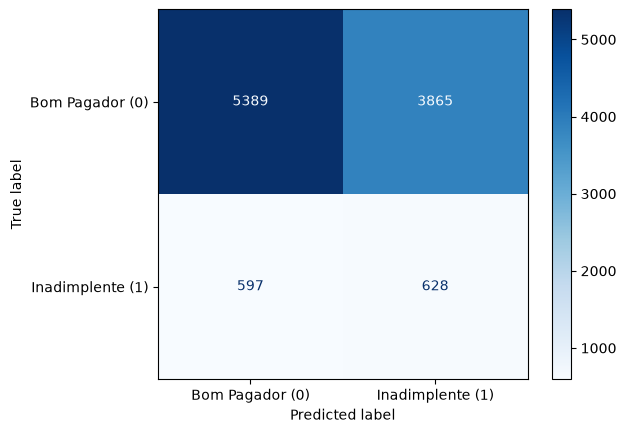

In [48]:
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred, 
    display_labels=['Bom Pagador (0)', 'Inadimplente (1)'], 
    cmap='Blues', 
    values_format='d'
)
plt.show()

In [49]:
print("\n--- Relatório de Classificação ---")
print(classification_report(y_test, y_pred))


--- Relatório de Classificação ---
              precision    recall  f1-score   support

           0       0.90      0.58      0.71      9254
           1       0.14      0.51      0.22      1225

    accuracy                           0.57     10479
   macro avg       0.52      0.55      0.46     10479
weighted avg       0.81      0.57      0.65     10479



In [50]:
print(f"\nROC AUC Score: {roc_auc_score(y_test, y_prob):.4f}")


ROC AUC Score: 0.5474


In [51]:
coeficientes = pd.DataFrame({
    'Feature': X_encoded.columns,
    'Coeficiente': modelo_lr.coef_[0]
}).sort_values(by='Coeficiente', ascending=False)

In [52]:
print("\n--- Top 5 Fatores que Aumentam o Risco ---")
print(coeficientes.head(5))


--- Top 5 Fatores que Aumentam o Risco ---
                               Feature  Coeficiente
3                       esta_empregado     1.071513
14    escolaridade_Superior_Incompleto     0.071061
11  escolaridade_Ensino_Médio__Técnico     0.069150
30        ocupacao_Equipe_de_Segurança     0.062699
33                   ocupacao_Gerentes     0.052933


In [53]:
print("\n--- Top 5 Fatores que Diminuem o Risco ---")
print(coeficientes.tail(5))


--- Top 5 Fatores que Diminuem o Risco ---
                           Feature  Coeficiente
39      ocupacao_Serviços_Privados    -0.056240
5                  possui_imovel_Y    -0.082038
10     tipo_renda_Servidor_Público    -0.750486
7   tipo_renda_Autônomo__Comercial    -1.180972
8             tipo_renda_Empregado    -1.462056


In [54]:
### XGboost

In [55]:
peso_classes = y_train.value_counts()[0] / y_train.value_counts()[1]

In [56]:
modelo_xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=5,
    scale_pos_weight=peso_classes,
    random_state=42,
    eval_metric='logloss'
)
modelo_xgb.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [57]:
y_pred_xgb = modelo_xgb.predict(X_test)
y_prob_xgb = modelo_xgb.predict_proba(X_test)[:, 1]

In [58]:
print("--- Relatório de Classificação (XGBoost) ---")
print(classification_report(y_test, y_pred_xgb))
print(f"ROC AUC Score: {roc_auc_score(y_test, y_prob_xgb):.4f}\n")

--- Relatório de Classificação (XGBoost) ---
              precision    recall  f1-score   support

           0       0.93      0.72      0.81      9254
           1       0.21      0.56      0.30      1225

    accuracy                           0.70     10479
   macro avg       0.57      0.64      0.56     10479
weighted avg       0.84      0.70      0.75     10479

ROC AUC Score: 0.6838



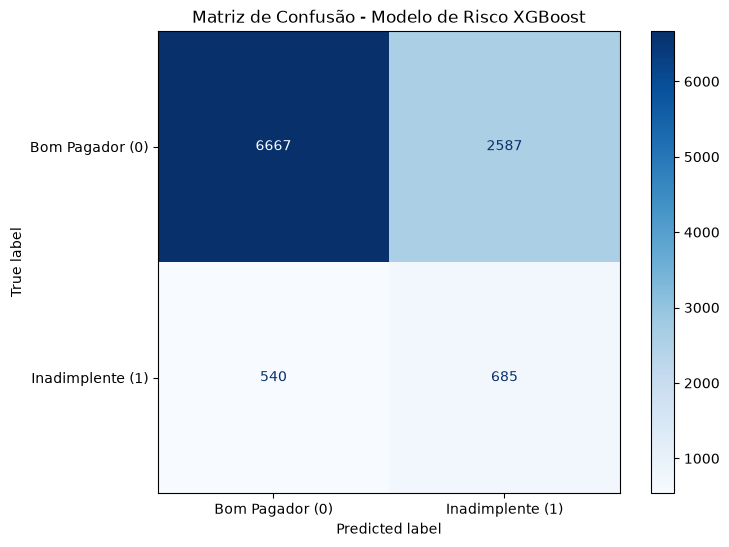

In [59]:
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_xgb, 
    display_labels=['Bom Pagador (0)', 'Inadimplente (1)'],
    cmap='Blues',       
    values_format='d',  
    ax=ax
)
plt.title('Matriz de Confusão - Modelo de Risco XGBoost')
plt.show()

Parâmetros da Regressão Logística

max_iter=1000: Aumenta o limite de iterações matemáticas para garantir que o algoritmo de otimização tenha tempo suficiente para encontrar os melhores coeficientes (convergir) antes de encerrar.

class_weight='balanced': Força o modelo a penalizar mais severamente os erros cometidos na minoria (inadimplentes), ajustando os pesos matemáticos de forma inversamente proporcional à frequência das classes na base.

random_state=42: Trava a semente de aleatoriedade, garantindo que o modelo produza exatamente o mesmo resultado se o código for rodado novamente.

Parâmetros do XGBoost

n_estimators=200: Define a criação de 200 árvores de decisão sequenciais. Cada nova árvore tenta corrigir os erros residuais deixados por todas as árvores anteriores.

learning_rate=0.1: Controla o passo de aprendizado. Um valor de 0.1 reduz o impacto de cada árvore individual, exigindo que o modelo aprenda de forma mais lenta e conservadora para evitar o sobreajuste (overfitting) aos dados de treino.

max_depth=5: Limita a profundidade de cada árvore a 5 ramificações. Isso impede que o modelo crie regras complexas demais focadas em ruídos específicos da base.

scale_pos_weight=peso_classes: É o equivalente do XGBoost para lidar com dados desbalanceados. Ele aplica um multiplicador de peso à classe positiva (inadimplentes) para compensar a predominância de bons pagadores.

eval_metric='logloss': Define a perda logarítmica como a métrica de avaliação interna durante a construção das árvores, adequada para otimizar probabilidades em classificações binárias.

O XGBoost vence a Regressão Logística por entregar o melhor equilíbrio entre proteção contra calotes e aprovação comercial.

Proteção do Capital (Recall da Classe 1)
O XGBoost barrou 56% dos maus pagadores reais, contra 51% da Logística. Ele reduz a aprovação indevida de crédito (falsos negativos), evitando perdas financeiras.

Geração de Negócios (Recall da Classe 0)
O XGBoost aprovou corretamente 72% dos bons clientes, enquanto o modelo anterior aprovou apenas 58%. Isso significa destravar milhares de concessões seguras e parar de rejeitar clientes rentáveis por excesso de conservadorismo (falsos positivos).

Assertividade do Bloqueio (Precision da Classe 1)
Quando o XGBoost acende o alerta de risco e nega o crédito, ele é significativamente mais exato (21% de acerto contra 14%), gerando menos alarmes falsos para a operação.

Poder de Separação (ROC AUC)
O score de 0.68 confirma que o modelo baseado em árvores consegue mapear comportamentos complexos dos clientes, separando com muito mais clareza os bons dos maus pagadores em comparação às limitações de um modelo puramente linear.